# Step 2. Data Cleaning & Integration
## Moneyball 2.0 — единый исторический датасет

**Результат:** очищенная таблица мужчин-CM с характеристиками FIFA 23 и положительной оценкой Transfermarkt на **26.09.2022**. Одна строка — один игрок на одну дату. Это дата выпуска FIFA 23 в выбранном legacy-срезе, а не календарный 2023 год.

Notebook читает исходные ZIP, повторно очищает таблицы и сопоставляет игроков. Готовый обучающий CSV из Step 1 не используется как вход. Все выводы и графики создаются кодом.

Этапы: контроль источников → очистка пропусков/дублей → нормализация позиций → сопоставление → датированный join → явные причины исключения → проверки → экспорт CSV и manifest.

Сохраняем контракт [Feature Set v1](../config/feature_set_v1.json): 18 игровых характеристик для сходства, 27 исходных входов для оценки стоимости. Обучение, масштабирование, one-hot и заполнение медианой выполняются позднее внутри train-fold.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/feature_set_v1.json").exists())
sys.path.insert(0, str(ROOT / "scripts"))
from audit_moneyball_join import match
CONTRACT = json.loads((ROOT / "config/feature_set_v1.json").read_text(encoding="utf-8"))
CUTOFF = CONTRACT["primary_snapshot"]["fifa_update_date"]
MAX_VALUE_AGE_DAYS = CONTRACT["target"]["max_staleness_days"]
CORE = CONTRACT["similarity_features"]
FEATURES = CORE + CONTRACT["valuation_additional_numeric_features"] + CONTRACT["valuation_additional_categorical_features"]
OUTPUT = ROOT / "data/processed/preprocessing"
OUTPUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 35)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
figures = []

def show(fig, name):
    fig.savefig(OUTPUT / f"{name}.png", dpi=135, bbox_inches="tight")
    figures.append(name)
    plt.show()
    plt.close(fig)

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

assert len(FEATURES) == len(set(FEATURES)) == 27
display(pd.DataFrame({"parameter": ["cutoff", "FIFA version", "population", "max valuation age", "feature contract"],
                      "value": [CUTOFF, "23", "male; exact CM token", str(MAX_VALUE_AGE_DAYS), CONTRACT["version"]]}))


,parameter,value
0,cutoff,2022-09-26
1,FIFA version,23
2,population,male; exact CM token
3,max valuation age,365
4,feature contract,1.0.0


### 1. Источники и контроль неизменности

Архивы ищутся в `MONEYBALL_DATA_DIR`, `data/raw/`, затем `~/Downloads`. SHA-256 должен совпасть с полным аудитом Step 1; при изменении архива выполнение останавливается.

Объединяются только необходимые таблицы: FIFA players, TM profiles **для идентификации**, TM market value **для исторической оценки**. Текущие клуб/контракт/позиция TM, latest value, сборные и teammates не присоединяются к признакам. Итоги выступлений и травмы исключены из обязательного v1 из-за покрытия и отсутствия версий момента публикации. Поэтому будущих выступлений в итоговой таблице нет.


In [2]:
from profile_moneyball_data import ARCHIVES
folders = ([Path(os.environ["MONEYBALL_DATA_DIR"])] if os.environ.get("MONEYBALL_DATA_DIR") else [])
folders += [ROOT / "data/raw", Path.home() / "Downloads"]
sources = {}
source_records = []
for source in ["fifa_male", "transfermarkt"]:
    filename = ARCHIVES[source]
    path = next((folder / filename for folder in folders if (folder / filename).exists()), None)
    if path is None:
        raise FileNotFoundError(f"Не найден {filename}; задайте MONEYBALL_DATA_DIR.")
    manifest = json.loads((ROOT / f"reports/data_profiling/{source}_archive.json").read_text(encoding="utf-8"))
    actual_hash = sha256(path)
    assert actual_hash == manifest["sha256"], f"Источник {source} изменился: сначала повторите Step 1."
    sources[source] = path
    source_records.append({"source": source, "archive": filename, "sha256": actual_hash})

def read_csv(source, member):
    with zipfile.ZipFile(sources[source]) as z:
        return pd.read_csv(z.open(member), dtype=str, na_filter=False)

fifa_all = read_csv("fifa_male", "male_players (legacy).csv")
fifa_raw = fifa_all.loc[fifa_all.fifa_version.eq("23") & fifa_all.fifa_update_date.eq(CUTOFF)].copy()
tm_raw = read_csv("transfermarkt", "player_profiles/player_profiles.csv")
values_raw = read_csv("transfermarkt", "player_market_value/player_market_value.csv")
assert len(fifa_raw) > 0
display(pd.DataFrame({"table": ["FIFA legacy all", "FIFA selected snapshot", "TM profiles", "TM value history"],
                      "rows": [len(fifa_all), len(fifa_raw), len(tm_raw), len(values_raw)]}))
del fifa_all


,table,rows
0,FIFA legacy all,161583
1,FIFA selected snapshot,18533
2,TM profiles,92671
3,TM value history,901429


### 2. Политика очистки

- Пустые/пробельные поля и явные `N/A`, `NULL`, `None`, `NaN`, `-`, `?` → missing. Реальные числовые нули не заменяются массово.
- Точные дубли удаляются. Если один бизнес-ключ содержит разные записи, **все конфликтующие строки помещаются в карантин**, вместо произвольного `keep='last'`.
- Некорректные ID, даты, невозможные характеристики не исправляются догадками.
- Рост TM `0` → unknown: он не участвует в проверке расхождения роста. TM используется для связи; признаки роста и веса берутся из FIFA на cutoff.
- Отсутствующая цена не заполняется FIFA-ценой, нулём или будущей оценкой. Нулевая последняя оценка исключается без отката к более старой положительной.


In [3]:
cleaning_log = []
quarantine_parts = []

def normalize_missing(frame):
    result = frame.copy()
    for col in result:
        result[col] = result[col].astype("string").str.strip()
        result[col] = result[col].mask(result[col].isin(["", "N/A", "NULL", "null", "None", "NaN", "nan", "-", "?"]))
    return result

def choose(conditions, labels, default=""):
    # Nullable pandas booleans must be explicit numpy bool arrays for np.select.
    masks = [c.fillna(False).to_numpy(dtype=bool) for c in conditions]
    return np.select(masks, labels, default=default)

def deduplicate(frame, key, name):
    exact = int(frame.duplicated().sum())
    result = frame.drop_duplicates().copy()
    conflict = result.duplicated(key, keep=False)
    if conflict.any():
        bad = result.loc[conflict].copy()
        bad["source_table"], bad["reason"] = name, "conflicting_business_key"
        quarantine_parts.append(bad)
    cleaning_log.append({"table": name, "input_rows": len(frame), "exact_duplicates_removed": exact,
                         "conflicting_rows_quarantined": int(conflict.sum()), "output_rows": int((~conflict).sum())})
    return result.loc[~conflict].copy()

fifa = deduplicate(normalize_missing(fifa_raw), ["player_id", "fifa_version", "fifa_update"], "fifa_snapshot")
tm = deduplicate(normalize_missing(tm_raw), ["player_id"], "tm_profiles")
values = deduplicate(normalize_missing(values_raw), ["player_id", "date_unix"], "tm_market_value")

for frame, name in [(fifa, "fifa"), (tm, "tm"), (values, "values")]:
    valid = frame.player_id.str.fullmatch(r"\d+", na=False)
    assert valid.all(), f"Invalid player ID in {name}; quarantine before continuing."

tm["height"] = pd.to_numeric(tm.height, errors="coerce")
tm.loc[~tm.height.between(120, 230), "height"] = np.nan
display(pd.DataFrame(cleaning_log))
display(pd.DataFrame({"TM field": ["height", "foot", "date_of_birth"],
                      "missing_after_cleaning": [int(tm[c].isna().sum()) for c in ["height", "foot", "date_of_birth"]]}))


,table,input_rows,exact_duplicates_removed,conflicting_rows_quarantined,output_rows
0,fifa_snapshot,18533,0,0,18533
1,tm_profiles,92671,0,0,92671
2,tm_market_value,901429,0,0,901429


,TM field,missing_after_cleaning
0,height,18872
1,foot,23488
2,date_of_birth,1006


### 3. Единый формат позиций и проверка FIFA-признаков

Список позиций приводится к верхнему регистру, удаляются повторы и лишние пробелы. Сохраняется порядок: первая позиция остаётся основной. Канонический CSV-формат — `CM|CDM|CAM`. `CAM` и `CDM` без отдельного `CM` не включаются.

Проверяются шкала игровых характеристик 1–99, дата рождения, возраст на cutoff, рост/вес, weak foot и категории work rate. Непригодные строки получают явную причину исключения.


,short_name,player_positions,player_positions_normalized,primary_position,is_primary_cm
143053,K. De Bruyne,"CM, CAM",CM|CAM,CM,True
143069,N. Kanté,"CDM, CM",CDM|CM,CDM,False
143070,L. Modrić,CM,CM,CM,True
143071,T. Kroos,CM,CM,CM,True
143076,Bernardo Silva,"CAM, CM",CAM|CM,CAM,False
143083,M. Verratti,"CM, CAM",CM|CAM,CM,True
143087,L. Goretzka,"CM, CDM",CM|CDM,CM,True
143090,F. de Jong,CM,CM,CM,True
143096,Thiago,CM,CM,CM,True
143097,Parejo,CM,CM,CM,True


,CM
feature_rejection_reason,
valid,4184


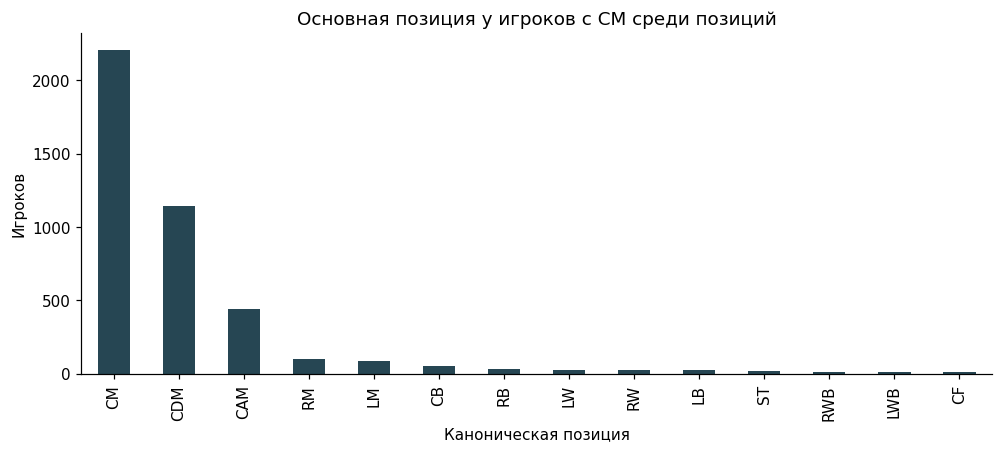

In [4]:
KNOWN_POSITIONS = {"GK", "CB", "LB", "RB", "LWB", "RWB", "CDM", "CM", "CAM", "LM", "RM", "LW", "RW", "CF", "ST"}
def position_tokens(value):
    if pd.isna(value):
        return []
    tokens = str(value).upper().replace("|", ",").split(",")
    return list(dict.fromkeys(t.strip() for t in tokens if t.strip()))

fifa["position_tokens"] = fifa.player_positions.map(position_tokens)
fifa["player_positions_normalized"] = fifa.position_tokens.map("|".join)
fifa["primary_position"] = fifa.position_tokens.map(lambda x: x[0] if x else "UNKNOWN")
fifa["is_cm"] = fifa.position_tokens.map(lambda x: "CM" in x)
fifa["is_primary_cm"] = fifa.primary_position.eq("CM")
valid_positions = fifa.position_tokens.map(lambda x: bool(x) and set(x).issubset(KNOWN_POSITIONS))

for column in CORE + ["height_cm", "weight_kg", "weak_foot", "league_level", "overall"]:
    fifa[column] = pd.to_numeric(fifa[column], errors="coerce")
dob = pd.to_datetime(fifa.dob, format="%Y-%m-%d", errors="coerce")
fifa["age_at_cutoff"] = (pd.Timestamp(CUTOFF) - dob).dt.days / 365.2425
work = fifa.work_rate.str.split("/", expand=True)
fifa["work_rate_attack"], fifa["work_rate_defence"] = work[0], work[1]
valid_core = fifa[CORE].notna().all(axis=1) & fifa[CORE].ge(1).all(axis=1) & fifa[CORE].le(99).all(axis=1)
valid_bio = (fifa.age_at_cutoff.between(15, 50) & fifa.height_cm.between(120, 230) & fifa.weight_kg.between(40, 140)
             & fifa.weak_foot.between(1, 5) & fifa.preferred_foot.isin(["Left", "Right"])
             & fifa.work_rate_attack.isin(["Low", "Medium", "High"]) & fifa.work_rate_defence.isin(["Low", "Medium", "High"]))
fifa["feature_valid"] = (valid_positions & valid_core & valid_bio).fillna(False).astype(bool)
fifa["feature_rejection_reason"] = choose([~valid_positions, ~valid_core, ~valid_bio.fillna(False)],
                                             ["invalid_positions", "missing_or_invalid_core", "invalid_biography"], default="")
cm = fifa.loc[fifa.is_cm].copy()
display(cm[["short_name", "player_positions", "player_positions_normalized", "primary_position", "is_primary_cm"]].head(10))
display(cm.feature_rejection_reason.replace("", "valid").value_counts().to_frame("CM"))

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
cm.primary_position.value_counts().plot.bar(ax=ax, color="#264653")
ax.set(title="Основная позиция у игроков с CM среди позиций", xlabel="Каноническая позиция", ylabel="Игроков")
show(fig, "01_primary_positions")


### 4. Сопоставление личностей

Используется проверенное в Step 1 правило: точный нормализованный алиас + точная дата рождения, единственный кандидат и взаимно однозначная связь. Расхождение роста >10 см и неоднозначные/нечёткие кандидаты направляются в отдельную очередь проверки. Клуб не обязан совпадать через несколько лет.

Сопоставляем весь выбранный FIFA-срез, затем фильтруем CM: так коллизии с другими игроками не скрываются фильтром позиции. Покрытие правила не является измеренной точностью — размеченного эталона нет.


In [5]:
# Matcher accepts source strings; missing TM height means no height check, not 0cm distance.
match_fifa = fifa[list(fifa_raw.columns)].astype(object)
match_fifa = match_fifa.where(match_fifa.notna(), "")
match_fifa["height_cm"] = pd.to_numeric(match_fifa.height_cm, errors="coerce").fillna(0)
assert match_fifa.player_id.is_unique
match_tm = tm.copy()
match_tm["height"] = match_tm.height.fillna(0).astype(str)
match_tm = match_tm.fillna("")
links, review = match(match_fifa, match_tm)
assert links.fifa_id.is_unique and links.tm_id.is_unique
joined = cm.rename(columns={"player_id": "fifa_id"}).merge(links, on="fifa_id", how="left", validate="one_to_one")
assert len(joined) == len(cm)
display(pd.DataFrame({"population": ["all FIFA players", "CM"],
                      "players": [len(fifa), len(cm)], "linked": [len(links), int(joined.tm_id.notna().sum())]}))
display(review.reason.value_counts().to_frame("candidate_rows"))


,population,players,linked
0,all FIFA players,18533,13261
1,CM,4184,3057


,candidate_rows
reason,
fuzzy_review_only,282
height_conflict_over_10cm,58
ambiguous_exact,1


### 5. Датированный join: последнее известное значение

Сначала удаляем негодные даты/значения, затем ограничиваем историю `date <= cutoff`, выбираем последнюю запись на игрока и выполняем many-to-one join. Только **после** выбора последней записи проверяем положительность и давность. Отбор положительных значений до выбора даты мог бы скрыть последнюю нулевую оценку.

Конфликтный ключ player–date не восстанавливается более ранней оценкой: игрок блокируется, если конфликт потенциально влияет на последнюю историческую запись. В текущем источнике конфликтов нет.


In [6]:
values["parsed_date"] = pd.to_datetime(values.date_unix, format="%Y-%m-%d", errors="coerce")
values["numeric_value"] = pd.to_numeric(values.value, errors="coerce")
births = pd.to_datetime(tm.set_index("player_id").date_of_birth, format="%Y-%m-%d", errors="coerce")
value_births = values.player_id.map(births)
bad_value = (values.parsed_date.isna() | values.numeric_value.isna() | ~np.isfinite(values.numeric_value)
             | values.numeric_value.lt(0) | (value_births.notna() & values.parsed_date.lt(value_births)))
bad_values = values.loc[bad_value].copy()
values_valid = values.loc[~bad_value].copy()

def historical_values(frame, cutoff):
    eligible = frame.loc[frame.parsed_date.le(pd.Timestamp(cutoff))].copy()
    eligible = eligible.sort_values(["player_id", "parsed_date"]).drop_duplicates("player_id", keep="last")
    return eligible[["player_id", "date_unix", "numeric_value"]].rename(
        columns={"player_id": "tm_id", "date_unix": "market_value_date", "numeric_value": "tm_market_value"})

historical = historical_values(values_valid, CUTOFF)
assert historical.tm_id.is_unique
joined = joined.merge(historical, on="tm_id", how="left", validate="many_to_one")
assert len(joined) == len(cm)
joined["market_value_age_days"] = (pd.Timestamp(CUTOFF) - pd.to_datetime(joined.market_value_date)).dt.days

# Conservative handling of invalid or conflicting known history: never silently fall back.
blocked_ids = set(values.loc[bad_value & (values.parsed_date.isna() | values.date_unix.le(CUTOFF).fillna(False)), "player_id"])
for part in quarantine_parts:
    if part.source_table.iloc[0] == "tm_market_value":
        blocked_ids.update(part.loc[part.date_unix.le(CUTOFF).fillna(False), "player_id"])
joined["valuation_blocked"] = joined.tm_id.isin(blocked_ids)
valid_price = joined.tm_market_value.gt(0) & joined.market_value_age_days.between(0, MAX_VALUE_AGE_DAYS)
joined["status"] = choose([
    ~joined.feature_valid, joined.tm_id.isna(), joined.valuation_blocked, joined.tm_market_value.isna(),
    joined.tm_market_value.eq(0), joined.market_value_age_days.gt(MAX_VALUE_AGE_DAYS), valid_price],
    ["invalid_features", "no_identity_link", "invalid_or_conflicting_value_history", "no_value_before_cutoff",
     "zero_value", "stale_value", "included"], default="unclassified")
assert not joined.status.eq("unclassified").any()
display(joined.status.value_counts().to_frame("CM"))
print("Future price rows excluded before join:", values_valid.parsed_date.gt(pd.Timestamp(CUTOFF)).sum())
assert joined.loc[joined.market_value_date.notna(), "market_value_date"].le(CUTOFF).all()


Future price rows excluded before join: 252736


,CM
status,
included,2886
no_identity_link,1127
no_value_before_cutoff,95
stale_value,69
zero_value,7


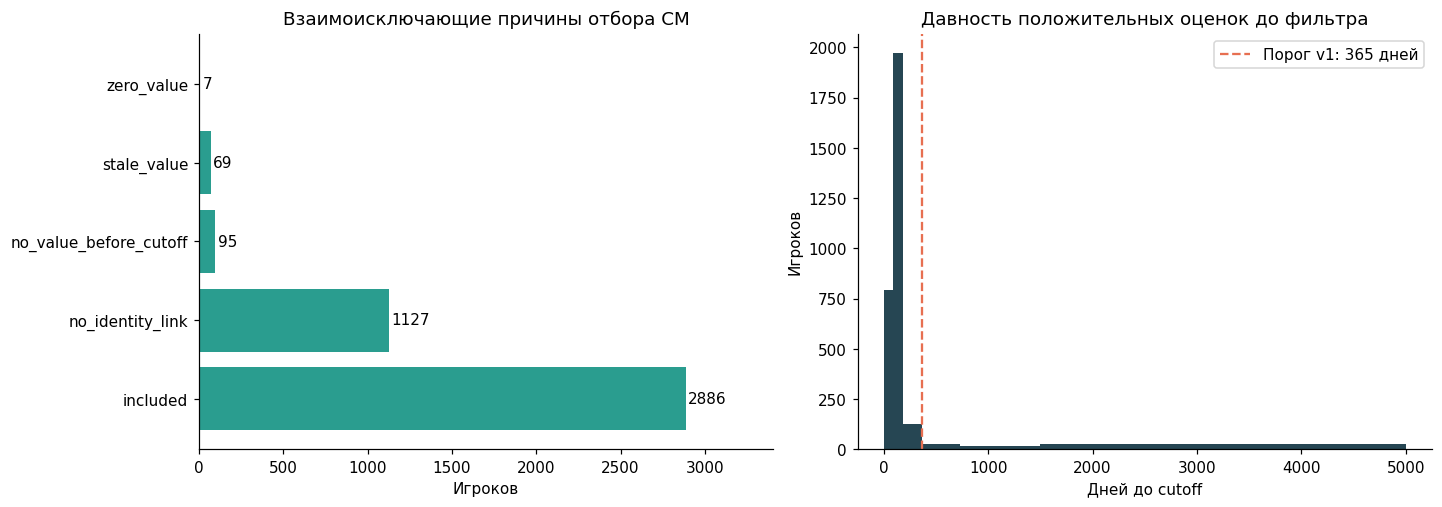

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
status_counts = joined.status.value_counts()
axes[0].barh(status_counts.index, status_counts.values, color="#2a9d8f")
axes[0].set(title="Взаимоисключающие причины отбора CM", xlabel="Игроков")
for i, n in enumerate(status_counts):
    axes[0].text(n + 15, i, str(n), va="center")
axes[0].set_xlim(0, status_counts.max() * 1.18)
axes[1].hist(joined.loc[joined.tm_market_value.gt(0), "market_value_age_days"], bins=[0,90,180,365,730,1500,5000], color="#264653")
axes[1].axvline(MAX_VALUE_AGE_DAYS, color="#e76f51", linestyle="--", label="Порог v1: 365 дней")
axes[1].set(title="Давность положительных оценок до фильтра", xlabel="Дней до cutoff", ylabel="Игроков")
axes[1].legend()
show(fig, "02_selection_and_staleness")


### 6. Итоговая схема и пропуски

В таблицу попадают только разрешённые признаки, цели и явные служебные поля. От TM не переносится никаких текущих характеристик игрока. `overall` сохраняется с ролью baseline; ID, имена, позиции и даты — metadata.

Неизвестный `league_id` → `UNKNOWN`. Невозможный/отсутствующий `league_level` остаётся missing с индикатором: медиана вычисляется **только после разбиения на train/test**. Это осознанное исключение, а не необработанный скрытый пропуск. В других модельных входах пропуски запрещены. Цена никогда не импутируется.


Shape: (2886, 47) ; raw model inputs: 27


,fifa_id,tm_id,as_of_date,fifa_version,fifa_update_date,market_value_date,market_value_age_days,short_name,long_name,dob,player_positions_normalized,primary_position,is_primary_cm,club_name,nationality_name,league_level_missing,market_value_currency,...,defending_marking_awareness,defending_standing_tackle,movement_acceleration,movement_sprint_speed,power_long_shots,age_at_cutoff,height_cm,weight_kg,weak_foot,league_level,preferred_foot,work_rate_attack,work_rate_defence,league_id,tm_market_value,target_log1p_tm_value,overall
0,134744,16101,2022-09-26,23,2022-09-26,2022-05-31,118.0,A. Hutchinson,Atiba Hutchinson,1983-02-08,CM|CDM,CM,True,Beşiktaş,Canada,False,source_units_unverified,...,73,74,55,49,60,39.631204,187,83,3,1,Right,Medium,Medium,68,275000.0,12.52453,72
1,137359,4742,2022-09-26,23,2022-09-26,2022-04-18,161.0,C. Lepoint,Christophe Lepoint,1984-10-24,CDM|CB|CM,CDM,False,RFC Seraing,Belgium,False,source_units_unverified,...,66,66,32,34,64,37.922750,188,83,3,1,Right,High,High,4,75000.0,11.225257,67
2,138412,3333,2022-09-26,23,2022-09-26,2022-06-14,104.0,J. Milner,James Philip Milner,1986-01-04,CM|LB|RB,CM,True,Liverpool,England,False,source_units_unverified,...,77,80,54,51,70,36.726285,175,70,4,1,Right,Medium,High,13,2000000.0,14.508658,78
3,138699,9967,2022-09-26,23,2022-09-26,2022-06-07,111.0,B. Džemaili,Blerim Džemaili,1986-04-12,CM|CDM,CM,True,Zürich,Switzerland,False,source_units_unverified,...,70,71,41,45,69,36.457970,180,80,4,1,Right,Medium,Medium,189,200000.0,12.206078,71
4,142499,71834,2022-09-26,23,2022-09-26,2022-06-28,90.0,Aitor Sanz,Aitor Sanz Martín,1984-09-13,CM|CDM,CM,True,Tenerife,Spain,False,source_units_unverified,...,73,74,63,45,65,38.035004,181,71,4,2,Right,Medium,High,54,100000.0,11.512935,72


,explicit_missing
league_level,7


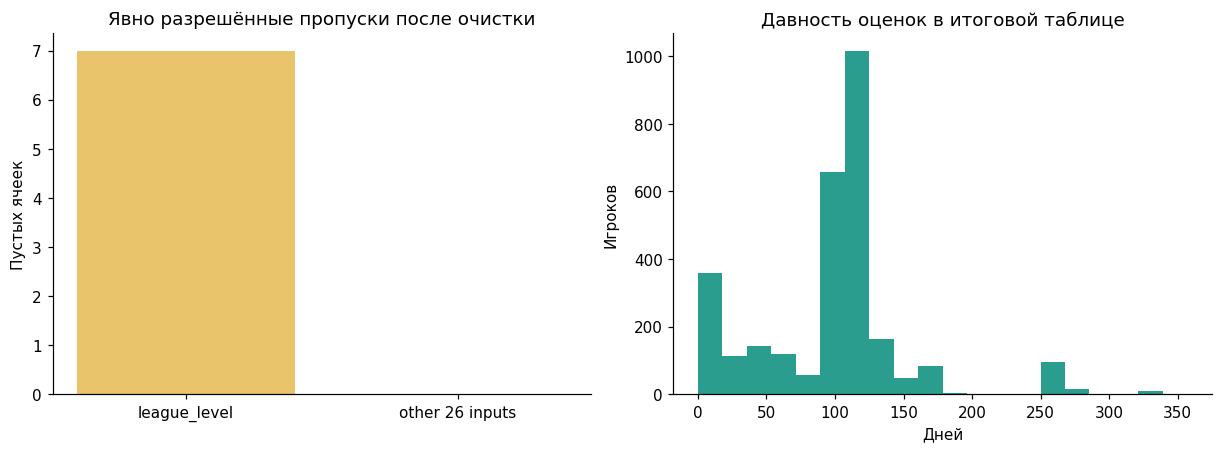

In [8]:
final = joined.loc[joined.status.eq("included")].copy()
final["league_id"] = final.league_id.fillna("UNKNOWN")
final.loc[~final.league_level.between(1, 10), "league_level"] = np.nan
final["league_level_missing"] = final.league_level.isna()
for column in ["short_name", "long_name", "club_name", "nationality_name"]:
    final[column] = final[column].fillna("UNKNOWN")
final["as_of_date"] = CUTOFF
final["target_log1p_tm_value"] = np.log1p(final.tm_market_value)
final["market_value_currency"] = "source_units_unverified"

metadata = ["fifa_id", "tm_id", "as_of_date", "fifa_version", "fifa_update_date", "market_value_date", "market_value_age_days",
            "short_name", "long_name", "dob", "player_positions_normalized", "primary_position", "is_primary_cm",
            "club_name", "nationality_name", "league_level_missing", "market_value_currency"]
targets = ["tm_market_value", "target_log1p_tm_value"]
baseline = ["overall"]
final = final[metadata + FEATURES + targets + baseline].sort_values("fifa_id").reset_index(drop=True)
display(final.head())
missing_features = final[FEATURES].isna().sum()
display(missing_features[missing_features.gt(0)].to_frame("explicit_missing"))
print("Shape:", final.shape, "; raw model inputs:", len(FEATURES))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].bar(["league_level", "other 26 inputs"], [int(final.league_level.isna().sum()), int(final[[c for c in FEATURES if c != 'league_level']].isna().sum().sum())], color="#e9c46a")
axes[0].set(title="Явно разрешённые пропуски после очистки", ylabel="Пустых ячеек")
axes[1].hist(final.market_value_age_days, bins=20, color="#2a9d8f")
axes[1].set(title="Давность оценок в итоговой таблице", xlabel="Дней", ylabel="Игроков")
show(fig, "03_final_missingness")


### 7. Контрольные примеры защиты от утечки

Помимо проверки реальных данных проверяем границы: CAM/CDM не равны CM; будущая запись не заменяет прошлую; нулевая последняя оценка не заменяется старой положительной; конфликтующие ключи не выбираются произвольно. Проверки выполняются до экспорта.


In [9]:
assert position_tokens(" cm , CDM, cm ") == ["CM", "CDM"]
assert "CM" not in position_tokens("CAM, CDM")
assert position_tokens(pd.NA) == []
assert choose([~pd.Series([pd.NA], dtype="boolean").fillna(False)], ["invalid_biography"])[0] == "invalid_biography"
fixture = pd.DataFrame({"player_id": ["A", "A", "A", "B"],
                        "date_unix": ["2022-01-01", CUTOFF, "2023-01-01", "2023-01-01"],
                        "numeric_value": [100., 0., 999., 500.]})
fixture["parsed_date"] = pd.to_datetime(fixture.date_unix)
fixture_result = historical_values(fixture, CUTOFF)
assert fixture_result.tm_id.tolist() == ["A"]
assert fixture_result.tm_market_value.iloc[0] == 0  # do not fall back to 100 or forward to 999
assert historical_values(fixture, "2021-12-31").empty
conflicting = pd.DataFrame({"player_id": ["A", "A", "B", "B"], "date_unix": [CUTOFF] * 4, "value": ["1", "2", "3", "3"]})
dedup_test = conflicting.drop_duplicates()
safe_test = dedup_test.loc[~dedup_test.duplicated(["player_id", "date_unix"], keep=False)]
assert safe_test.player_id.tolist() == ["B"]

checks = {
    "one_row_per_player": final.fifa_id.is_unique and final.tm_id.is_unique,
    "fixed_fifa_snapshot": final.fifa_update_date.eq(CUTOFF).all() and final.fifa_version.eq("23").all(),
    "no_future_price": final.market_value_date.le(CUTOFF).all(),
    "price_within_365_days": final.market_value_age_days.between(0, MAX_VALUE_AGE_DAYS).all(),
    "positive_finite_price": final.tm_market_value.gt(0).all() and np.isfinite(final.tm_market_value).all(),
    "exact_cm_token": final.player_positions_normalized.str.split("|").map(lambda x: "CM" in x).all(),
    "18_complete_core": final[CORE].notna().all().all(),
    "core_1_to_99": final[CORE].ge(1).all().all() and final[CORE].le(99).all().all(),
    "only_declared_missing_input": final[[f for f in FEATURES if f != "league_level"]].notna().all().all(),
    "missing_level_flag_correct": final.league_level_missing.eq(final.league_level.isna()).all(),
    "27_allowed_inputs": len(FEATURES) == 27 and set(FEATURES).issubset(final.columns),
    "no_fifa_financial_proxies": not set(["value_eur", "wage_eur", "release_clause_eur", "potential"]) & set(final.columns),
    "no_current_tm_or_performance_fields": not any(c.startswith(("current_", "prev_")) for c in final),
    "target_consistent": np.allclose(final.target_log1p_tm_value, np.log1p(final.tm_market_value)),
    "reconciled_selection": int(joined.status.value_counts().sum()) == len(cm),
}
assert all(checks.values()), {k: v for k,v in checks.items() if not v}
# Regression controls tied to the SHA-verified Step 1 source version.
assert len(cm) == 4184 and joined.tm_id.notna().sum() == 3057 and len(final) == 2886
assert final.league_level.isna().sum() == 7
display(pd.DataFrame({"check": checks.keys(), "passed": checks.values()}))


,check,passed
0,one_row_per_player,True
1,fixed_fifa_snapshot,True
2,no_future_price,True
3,price_within_365_days,True
4,positive_finite_price,True
5,exact_cm_token,True
6,18_complete_core,True
7,core_1_to_99,True
8,only_declared_missing_input,True
9,missing_level_flag_correct,True


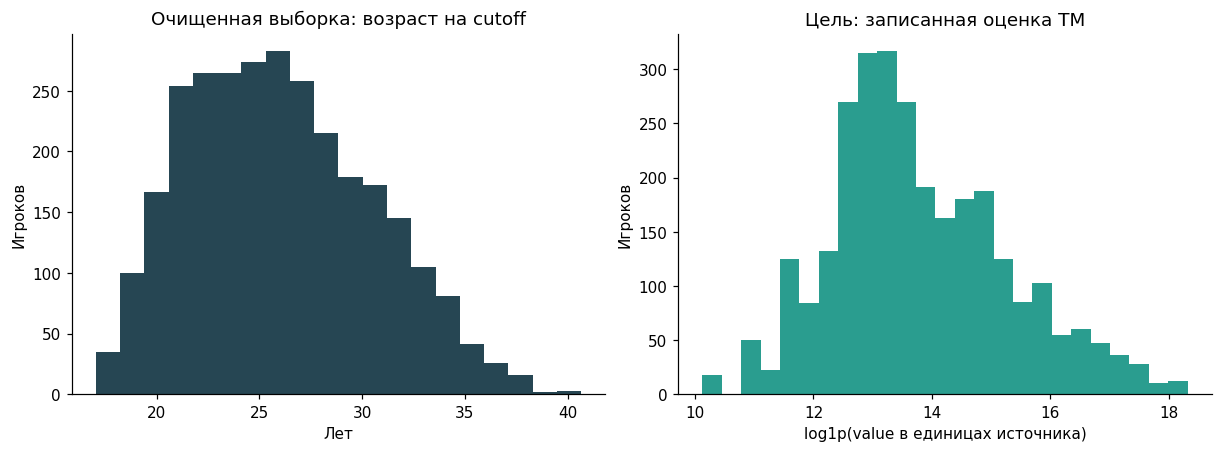

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].hist(final.age_at_cutoff, bins=20, color="#264653")
axes[0].set(title="Очищенная выборка: возраст на cutoff", xlabel="Лет", ylabel="Игроков")
axes[1].hist(final.target_log1p_tm_value, bins=25, color="#2a9d8f")
axes[1].set(title="Цель: записанная оценка TM", xlabel="log1p(value в единицах источника)", ylabel="Игроков")
show(fig, "04_final_distributions")


### 8. Экспорт и проверка чтения

Основной результат: `data/processed/preprocessing/moneyball_cm_2022-09-26_clean.csv`.

Рядом сохраняются schema/manifest с ролями колонок и контрольной суммой, журнал очистки, mapping, очередь ручной проверки, аудит отбора всех CM и карантин. Это локальные производные исходных данных; каталог `data/processed/` исключён из Git. Notebook содержит результаты и встроенные графики.

При обучении X выбирается только по `feature_columns` manifest. Цель, overall, даты, индикатор неизвестного уровня и прочие metadata автоматически в X не включаются.


In [11]:
dataset_path = OUTPUT / f"moneyball_cm_{CUTOFF}_clean.csv"
final.to_csv(dataset_path, index=False, encoding="utf-8", date_format="%Y-%m-%d")
links.to_csv(OUTPUT / "identity_mapping.csv", index=False)
review.to_csv(OUTPUT / "identity_review.csv", index=False)
joined[["fifa_id", "tm_id", "player_positions_normalized", "feature_rejection_reason", "status", "market_value_date", "market_value_age_days"]].to_csv(OUTPUT / "selection_audit.csv", index=False)
pd.DataFrame(cleaning_log).to_csv(OUTPUT / "cleaning_log.csv", index=False)
quarantine = pd.concat(quarantine_parts, ignore_index=True) if quarantine_parts else pd.DataFrame(columns=["source_table", "reason"])
quarantine.to_csv(OUTPUT / "conflicting_keys.csv", index=False)
bad_values.to_csv(OUTPUT / "invalid_market_values.csv", index=False)

loaded = pd.read_csv(dataset_path, dtype={"fifa_id": str, "tm_id": str, "league_id": str})
assert loaded.shape == final.shape and loaded.fifa_id.is_unique and loaded.tm_id.is_unique
assert loaded.fifa_id.tolist() == final.fifa_id.tolist()
assert np.allclose(loaded.tm_market_value, final.tm_market_value)
assert np.allclose(loaded.target_log1p_tm_value, final.target_log1p_tm_value)
assert loaded.market_value_date.le(CUTOFF).all()
assert loaded[CORE].notna().all().all()
assert loaded.league_level.isna().sum() == final.league_level.isna().sum()

manifest = {
    "dataset": dataset_path.name, "sha256": sha256(dataset_path), "rows": len(final), "columns": len(final.columns),
    "as_of_date": CUTOFF, "feature_contract": CONTRACT["version"], "feature_columns": FEATURES,
    "metadata_columns": metadata, "target_columns": targets, "baseline_columns": baseline,
    "column_dtypes": {c: str(final[c].dtype) for c in final}, "sources": source_records,
    "selection_counts": {str(k): int(v) for k,v in joined.status.value_counts().items()},
    "missing_features": {c: int(final[c].isna().sum()) for c in FEATURES if final[c].isna().any()},
    "missing_policy": "league_id UNKNOWN; league_level missing + flag; fit median only on training fold; never impute target",
    "currency": "source units, not independently certified EUR",
    "temporal_policy": "fixed FIFA snapshot; latest value <= cutoff; positive; age <=365 days; no performance/current TM inputs",
    "historical_limit": "retrospective event-date reconstruction; source knowledge-time revisions unavailable",
    "validation": {k: bool(v) for k,v in checks.items()}, "roundtrip_csv": "passed",
}
(OUTPUT / "dataset_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
display(Markdown(f"**Готово:** `{dataset_path.name}` — **{len(final):,} игроков**, {len(final.columns)} столбцов, "
                 f"**27 модельных входов**. Дата: **{CUTOFF}**. Все проверки и повторное чтение CSV пройдены. "
                 "Остались 7 явно разрешённых missing в league_level для последующего заполнения внутри train-fold."))
display(pd.DataFrame({"artifact": [dataset_path.name, "dataset_manifest.json", "selection_audit.csv", "identity_review.csv"],
                      "location": [str(OUTPUT.relative_to(ROOT))] * 4}))


**Готово:** `moneyball_cm_2022-09-26_clean.csv` — **2,886 игроков**, 47 столбцов, **27 модельных входов**. Дата: **2022-09-26**. Все проверки и повторное чтение CSV пройдены. Остались 7 явно разрешённых missing в league_level для последующего заполнения внутри train-fold.

,artifact,location
0,moneyball_cm_2022-09-26_clean.csv,data\processed\preprocessing
1,dataset_manifest.json,data\processed\preprocessing
2,selection_audit.csv,data\processed\preprocessing
3,identity_review.csv,data\processed\preprocessing
